In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("Telco_Customer_Churn_Dataset .csv")
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(df.shape)

(7043, 21)


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [5]:
churn_count = df['Churn'].value_counts()
print(churn_count)
churn_percentage = (
    df['Churn'].value_counts(normalize=True)  * 100)
print(churn_percentage)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


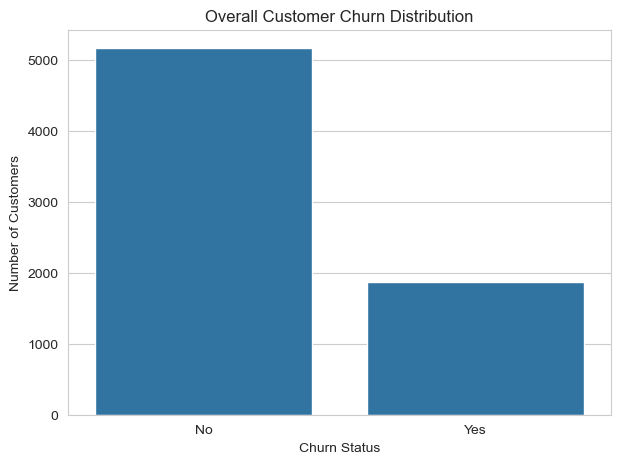

In [6]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='Churn')
plt.title('Overall Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.show()

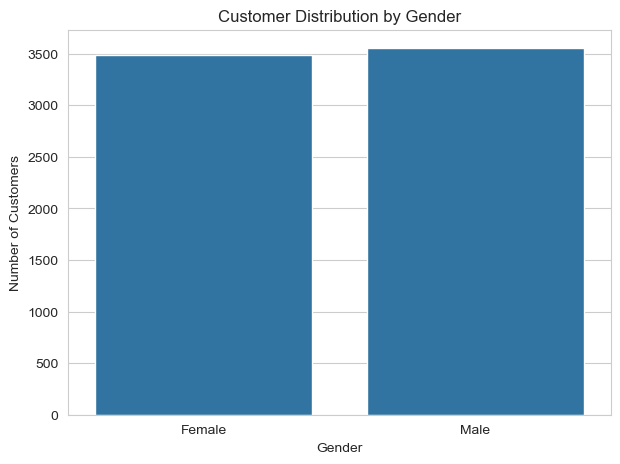

In [7]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='gender')
plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64


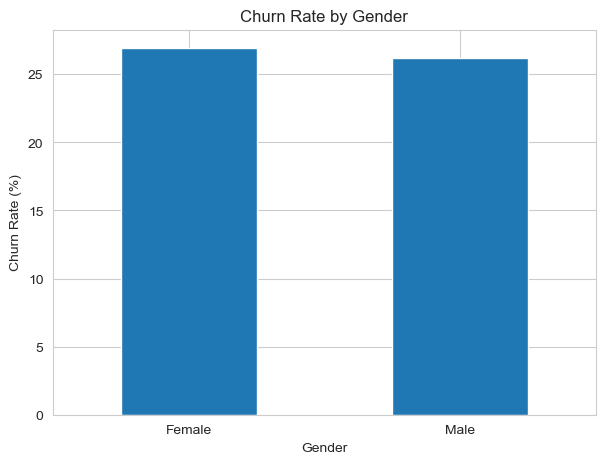

In [10]:
gender_churn_rate = (
    df.groupby('gender')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
print(gender_churn_rate)

plt.figure(figsize=(7, 5))
gender_churn_rate.plot(kind='bar')
plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [11]:
print( df['SeniorCitizen'].value_counts())
df['SeniorCitizenLabel'] = df['SeniorCitizen'].map({
    0: 'Non-Senior',
    1: 'Senior'})

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


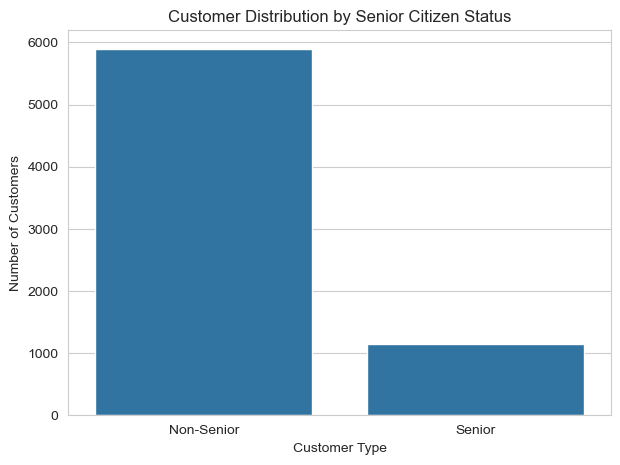

In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='SeniorCitizenLabel')
plt.title('Customer Distribution by Senior Citizen Status')
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')
plt.show()

SeniorCitizenLabel
Non-Senior    23.606168
Senior        41.681261
Name: Churn, dtype: float64


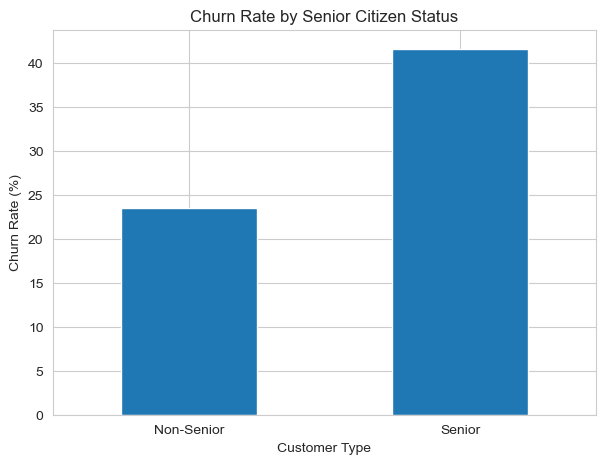

In [13]:
senior_churn = (
    df.groupby('SeniorCitizenLabel')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
print(senior_churn)

plt.figure(figsize=(7, 5))
senior_churn.plot(kind='bar')
plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Customer Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

Partner
No     32.957979
Yes    19.664903
Name: Churn, dtype: float64


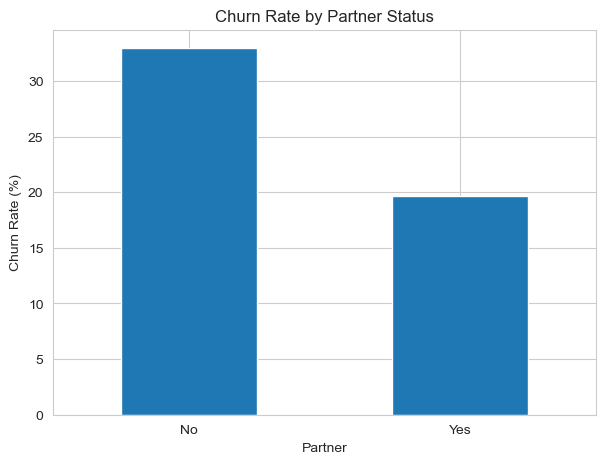

In [14]:
partner_churn = (
    df.groupby('Partner')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
print(partner_churn)

plt.figure(figsize=(7, 5))
partner_churn.plot(kind='bar')
plt.title('Churn Rate by Partner Status')
plt.xlabel('Partner')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

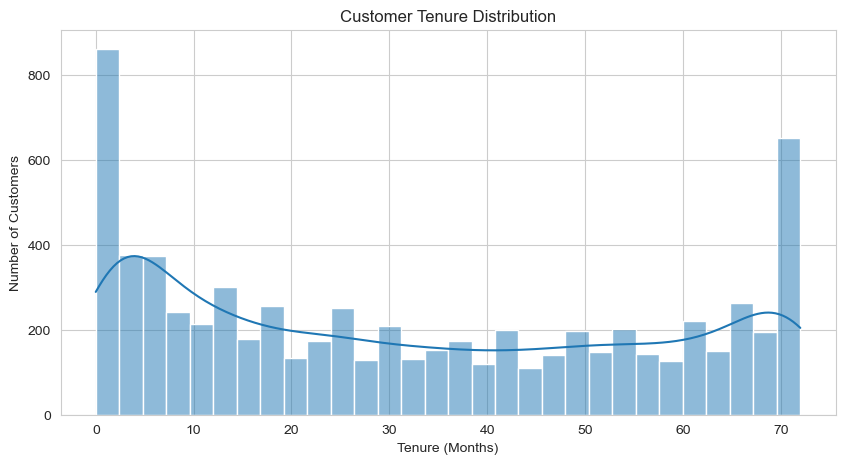

In [15]:
df['tenure'].describe()
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='tenure',
    bins=30,
    kde=True)
plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

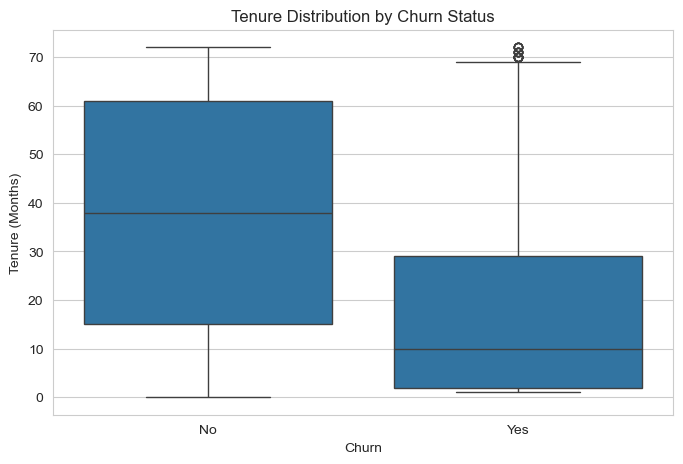

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure')
plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

In [17]:
tenure_by_churn = df.groupby('Churn')['tenure'].agg(
    ['mean', 'median', 'min', 'max'])
print(tenure_by_churn)

            mean  median  min  max
Churn                             
No     37.569965    38.0    0   72
Yes    17.979133    10.0    1   72


Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


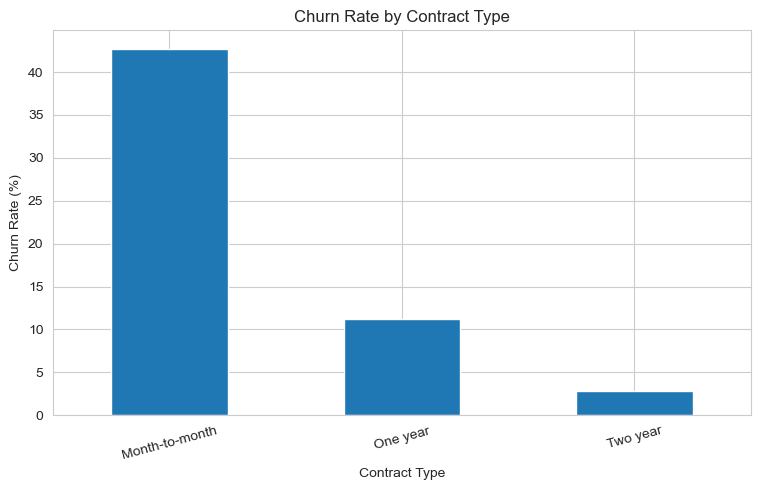

In [18]:
contract_churn = (  df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print(contract_churn)

plt.figure(figsize=(9, 5))
contract_churn.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.show()

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64


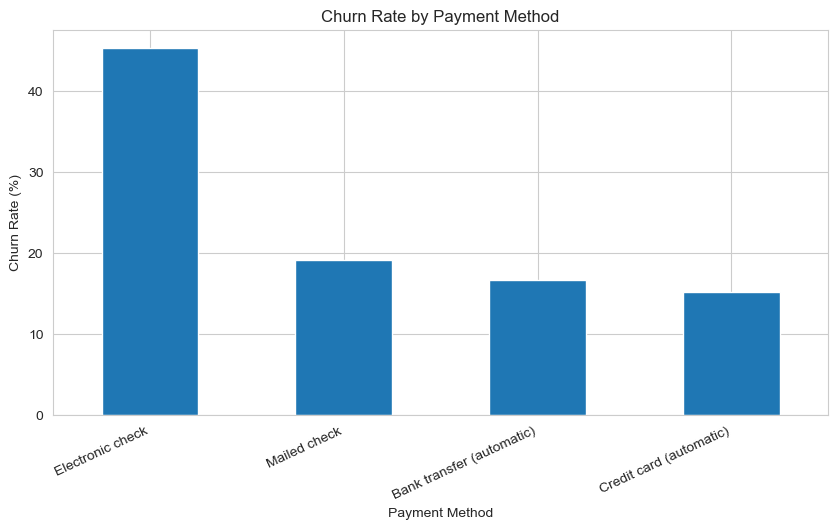

In [19]:
payment_churn = ( df.groupby('PaymentMethod')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print(payment_churn)

plt.figure(figsize=(10, 5))
payment_churn.plot(kind='bar')
plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=25, ha='right')
plt.show()

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64


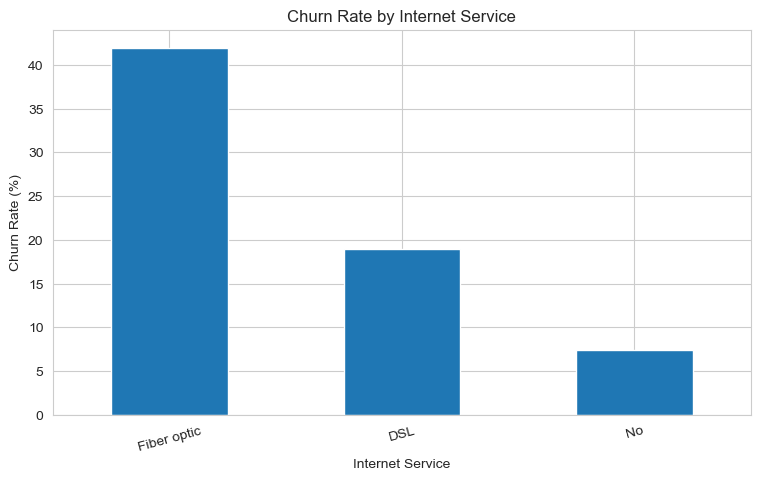

In [20]:
internet_churn = ( df.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print(internet_churn)

plt.figure(figsize=(9, 5))
internet_churn.plot(kind='bar')
plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.show()

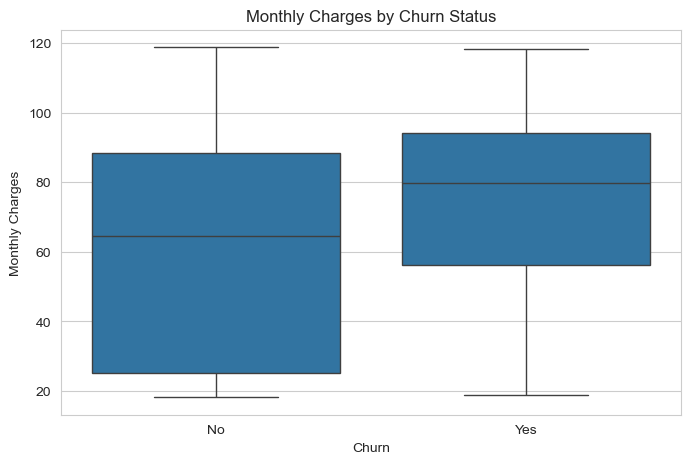

            mean  median
Churn                   
No     61.265124  64.425
Yes    74.441332  79.650


In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges')
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

monthly_charges_churn = (
    df.groupby('Churn')['MonthlyCharges']
    .agg(['mean', 'median']))
print(monthly_charges_churn)

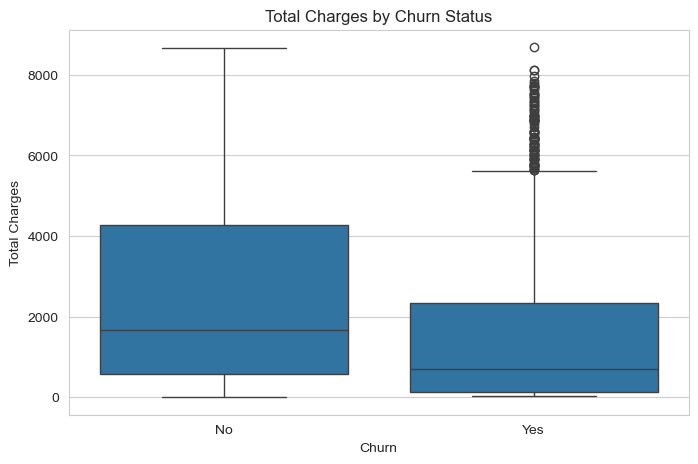

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges')
plt.title('Total Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Total Charges')
plt.show()

In [23]:
summary = pd.DataFrame({
    'Factor': [
        'Gender',
        'Senior Citizen',
        'Partner',
        'Contract',
        'Payment Method',
        'Internet Service'  ],
    'Analysis': [
        'Churn rate compared by gender',
        'Churn rate compared by senior status',
        'Churn rate compared by partner status',
        'Churn rate compared by contract type',
        'Churn rate compared by payment method',
        'Churn rate compared by internet service' ]})
summary

,Factor,Analysis
0,Gender,Churn rate compared by gender
1,Senior Citizen,Churn rate compared by senior status
2,Partner,Churn rate compared by partner status
3,Contract,Churn rate compared by contract type
4,Payment Method,Churn rate compared by payment method
5,Internet Service,Churn rate compared by internet service
